# 🏦 Universal Bank  Personal Loan Campaign Analysis
### Data Mining Project | Classification & Clustering v2

**Business objective:** a previous campaign converted **9.6%** of liability customers into personal-loan customers.
We want to **score customers by their probability of accepting**, so the next campaign can target fewer people while reaching most of the acceptors.

**Dataset:** 5,000 customers, demographic and banking attributes. **Target:** `PersonalLoan` (1 = accepted).

**What changed in v2**
- Column names aligned with the CSV; notebook fully executed (all numbers below are produced by the code).
- `Experience` column dropped instead of dropping rows (|ρ| = 0.99 with `Age`): all 5,000 customers are kept.
- Held-out test set + **stratified cross-validation** on the training set for model selection.
- **Logistic regression baseline** and a dummy baseline added.
- Metric adapted to class imbalance: **average precision (PR-AUC)** as the main criterion, plus precision / recall / F1.
- Decision threshold chosen on out-of-fold training predictions, never on the test set.
- Cumulative gains (lift) analysis for campaign targeting.
- K-Means: silhouette scores reported alongside the elbow curve.

**Structure:** 1. Loading & cleaning · 2. EDA · 3. Correlations · 4. K-Means segmentation · 5. Predictive modeling · 6. Conclusions & limitations

## 1. Data Loading & Cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, average_precision_score, roc_auc_score,
                             silhouette_score, f1_score, precision_score, recall_score)

SEED = 42
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

In [2]:
df = pd.read_csv('UniversalBank.csv')
print(f"Shape: {df.shape}")
print(f"Missing values: {df.isnull().sum().sum()}")
df.head()

Shape: (5000, 14)
Missing values: 0


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,PersonalLoan,SecuritiesAccount,CDAccount,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [3]:
# Data quality checks
print(f"Negative Experience values : {(df['Experience'] < 0).sum()}")
print(f"Correlation Age / Experience: {df['Age'].corr(df['Experience']):.3f}")
print(f"Distinct ZIP codes          : {df['ZIP Code'].nunique()}")

Negative Experience values : 52
Correlation Age / Experience: 0.994
Distinct ZIP codes          : 467


**Cleaning decisions**
- `ID`: identifier, no information → dropped.
- `ZIP Code`: 467 distinct values for 5,000 rows (high cardinality, ~10 customers per value) → dropped. A geographic aggregation (county) could be tested later.
- `Experience`: 52 negative values (entry errors) **and** almost perfectly correlated with `Age`. Rather than deleting 52 customers, we drop the redundant **column**: `Age` carries the same information.

In [4]:
df = df.drop(columns=['ID', 'ZIP Code', 'Experience'])
TARGET = 'PersonalLoan'
print(f"Final shape: {df.shape}")
df.describe().round(2)

Final shape: (5000, 11)


,Age,Income,Family,CCAvg,Education,Mortgage,PersonalLoan,SecuritiesAccount,CDAccount,Online,CreditCard
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,45.34,73.77,2.40,1.94,1.88,56.50,0.10,0.10,0.06,0.60,0.29
std,11.46,46.03,1.15,1.75,0.84,101.71,0.29,0.31,0.24,0.49,0.46
min,23.00,8.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,35.00,39.00,1.00,0.70,1.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,45.00,64.00,2.00,1.50,2.00,0.00,0.00,0.00,0.00,1.00,0.00
75%,55.00,98.00,3.00,2.50,3.00,101.00,0.00,0.00,0.00,1.00,1.00
max,67.00,224.00,4.00,10.00,3.00,635.00,1.00,1.00,1.00,1.00,1.00


## 2. Exploratory Data Analysis

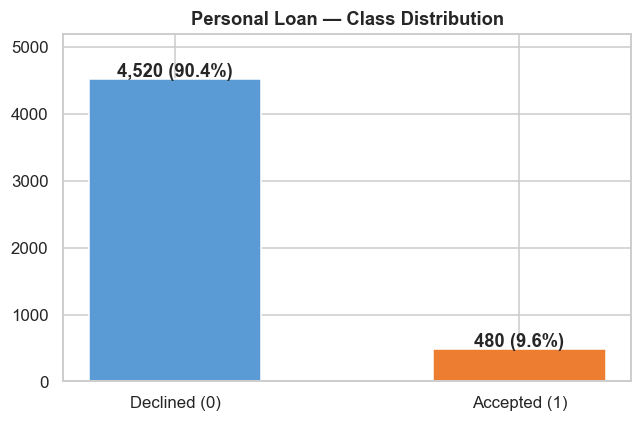

Positive rate: 9.6% -> a model predicting 'No' for everyone reaches 90.4% accuracy.


In [5]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Declined (0)', 'Accepted (1)'], counts.values, color=['#5B9BD5', '#ED7D31'], width=0.5)
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f'{v:,} ({v/counts.sum():.1%})', ha='center', fontweight='bold')
ax.set_title('Personal Loan — Class Distribution', fontweight='bold')
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); plt.show()
print(f"Positive rate: {df[TARGET].mean():.1%} -> a model predicting 'No' for everyone reaches {1-df[TARGET].mean():.1%} accuracy.")

The classes are **imbalanced** (9.6% positives). Accuracy is therefore misleading: a trivial model already scores 90.4%. We will evaluate on the **positive class** (precision, recall, F1, PR-AUC).

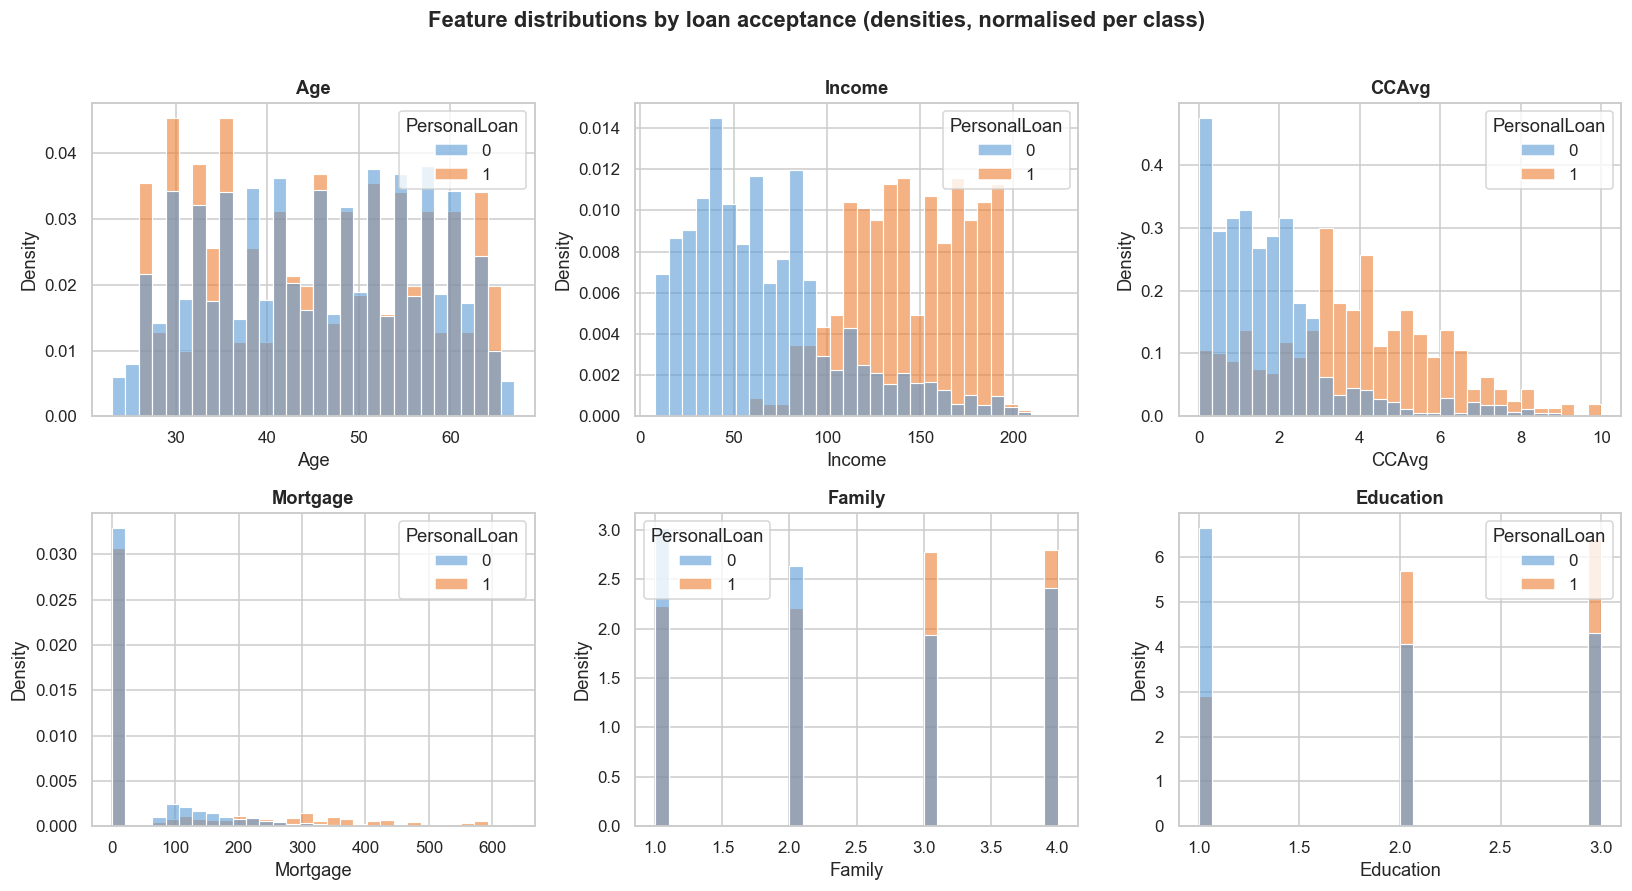

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.flat, ['Age', 'Income', 'CCAvg', 'Mortgage', 'Family', 'Education']):
    sns.histplot(data=df, x=feat, hue=TARGET, stat='density', common_norm=False,
                 bins=30, ax=ax, palette=['#5B9BD5', '#ED7D31'], alpha=0.6)
    ax.set_title(feat, fontweight='bold')
plt.suptitle('Feature distributions by loan acceptance (densities, normalised per class)', fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

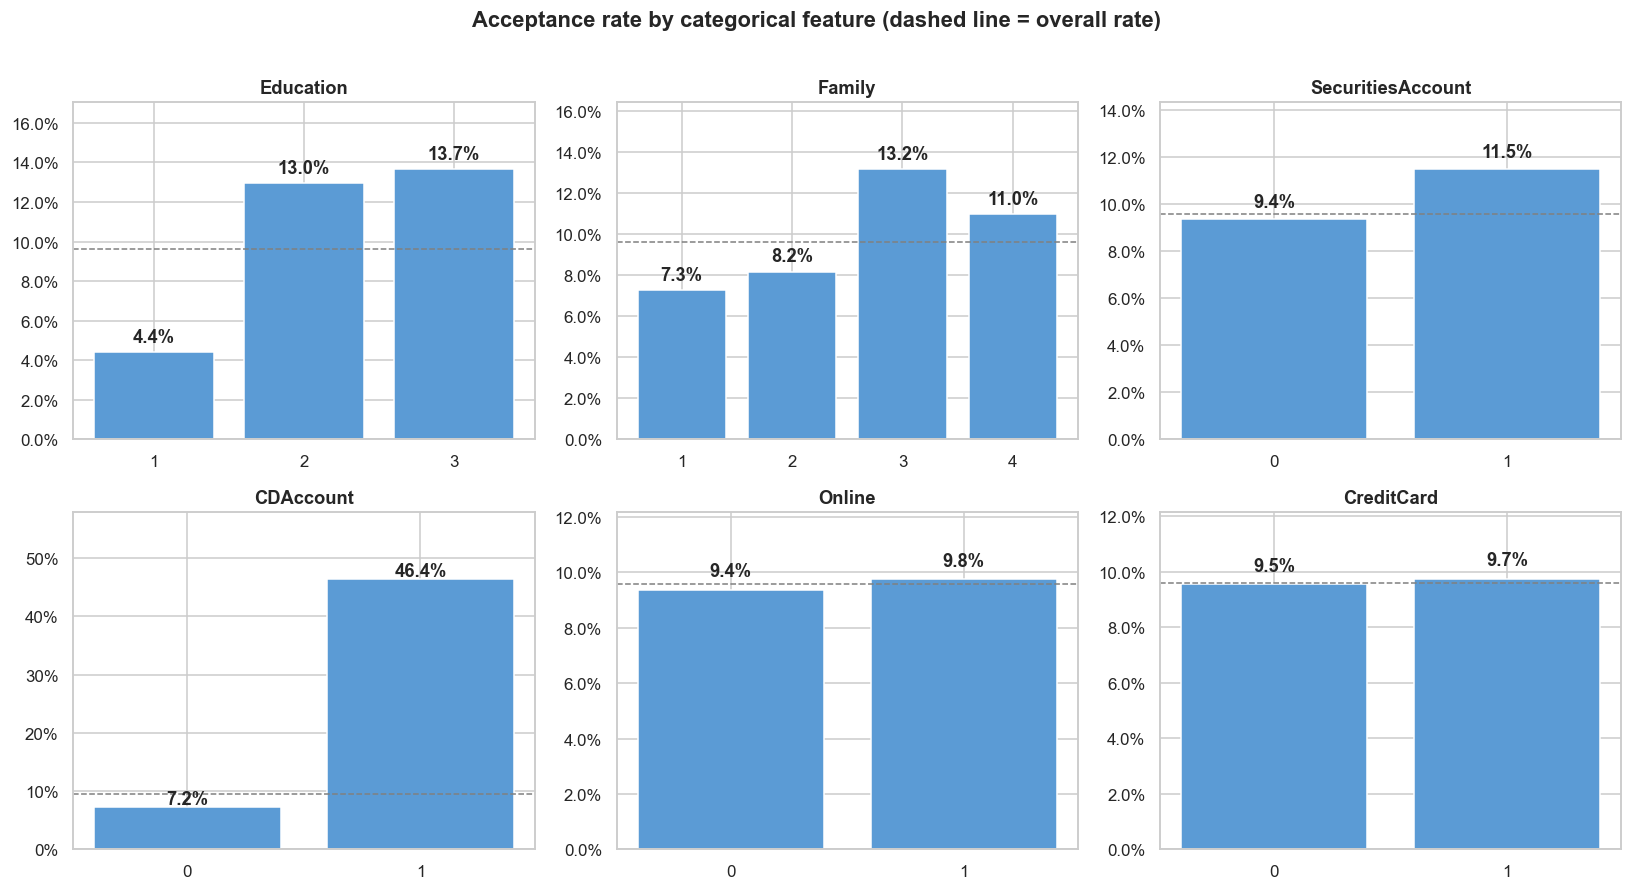

Education {1: 4.4, 2: 13.0, 3: 13.7}
Family {1: 7.3, 2: 8.2, 3: 13.2, 4: 11.0}
SecuritiesAccount {0: 9.4, 1: 11.5}
CDAccount {0: 7.2, 1: 46.4}
Online {0: 9.4, 1: 9.8}
CreditCard {0: 9.5, 1: 9.7}


In [7]:
cat_features = ['Education', 'Family', 'SecuritiesAccount', 'CDAccount', 'Online', 'CreditCard']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.flat, cat_features):
    rate = df.groupby(feat)[TARGET].mean() * 100
    bars = ax.bar(rate.index.astype(str), rate.values, color='#5B9BD5')
    for b, v in zip(bars, rate.values):
        ax.text(b.get_x() + b.get_width()/2, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')
    ax.axhline(df[TARGET].mean()*100, ls='--', color='grey', lw=1)
    ax.set_title(feat, fontweight='bold'); ax.set_ylim(0, rate.max()*1.25)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
plt.suptitle('Acceptance rate by categorical feature (dashed line = overall rate)', fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

for feat in cat_features:
    print(feat, (df.groupby(feat)[TARGET].mean()*100).round(1).to_dict())

In [8]:
high = df['Income'] > 100
print(f"Income > $100K : {high.sum():,} customers, acceptance rate {df.loc[high, TARGET].mean():.1%}")
print(f"Income <= $100K: {(~high).sum():,} customers, acceptance rate {df.loc[~high, TARGET].mean():.1%}")

Income > $100K : 1,212 customers, acceptance rate 36.1%
Income <= $100K: 3,788 customers, acceptance rate 1.1%


## 3. Feature Correlations

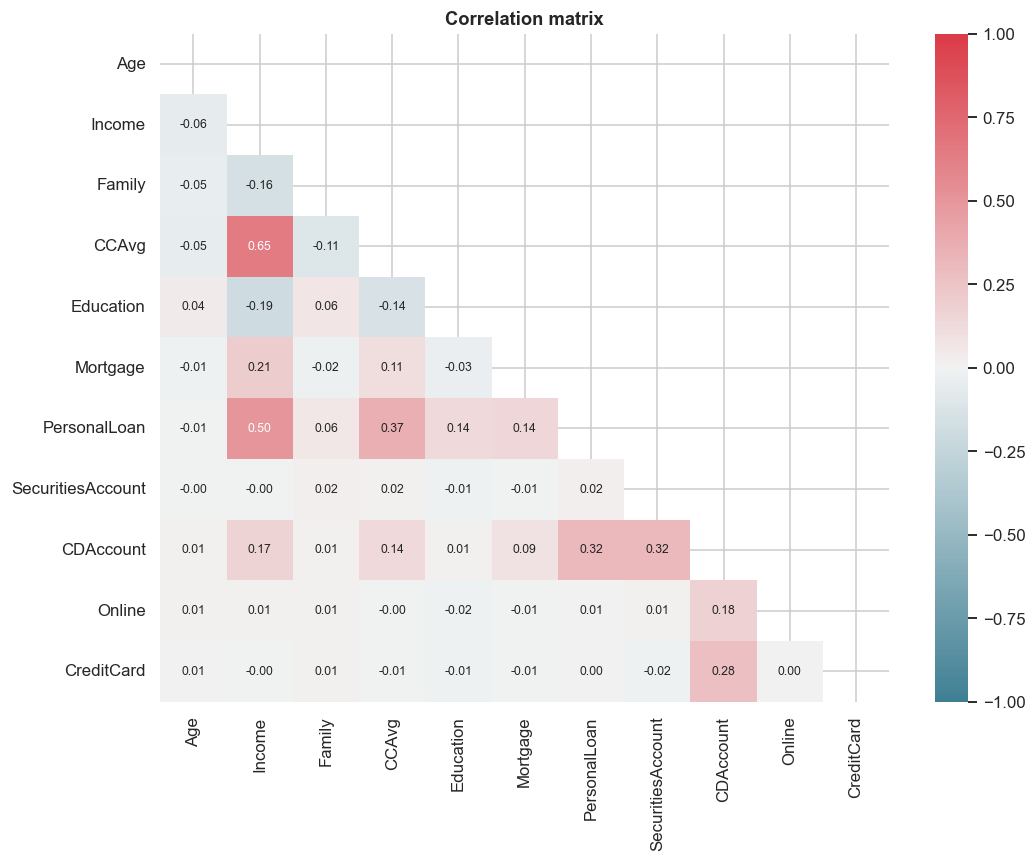

Income               0.502
CCAvg                0.367
CDAccount            0.316
Mortgage             0.142
Education            0.137
Family               0.061
SecuritiesAccount    0.022
Age                 -0.008
Online               0.006
CreditCard           0.003
Name: PersonalLoan, dtype: float64


In [9]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap=sns.diverging_palette(220, 10, as_cmap=True),
            annot=True, fmt='.2f', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlation matrix', fontweight='bold')
plt.tight_layout(); plt.show()
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

Pearson correlation only captures **linear, marginal** relationships. It ranks Income, CCAvg and CDAccount first; the models below will tell us what remains informative once all variables are combined.

## 4. Customer Segmentation — K-Means

Unsupervised segmentation on financial profile features (standardised), **without** the target. We then look at the acceptance rate in each segment.

  File "C:\Users\islam\Nouveau dossier\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\islam\Nouveau dossier\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\islam\Nouveau dossier\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\islam\Nouveau dossier\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


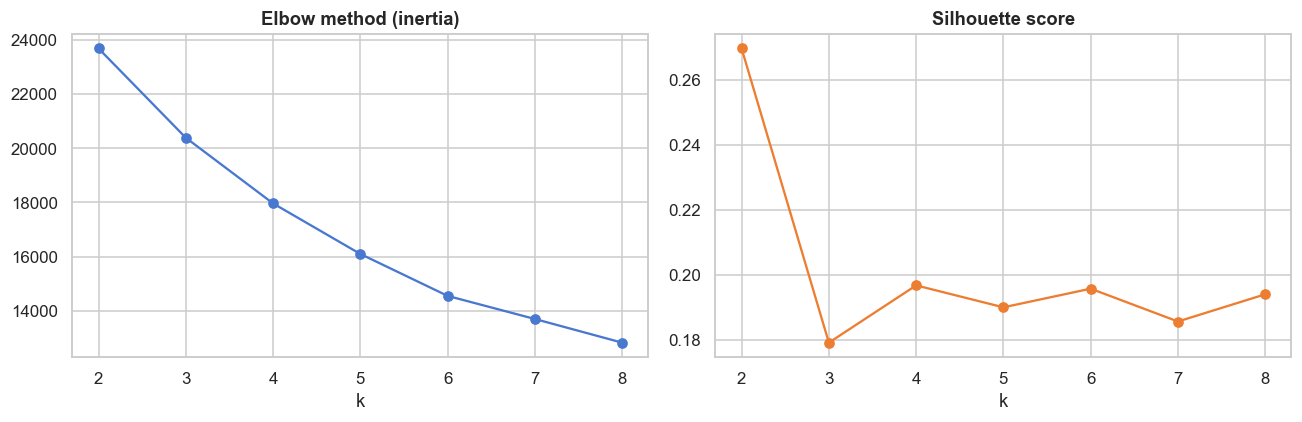

 k  inertia  silhouette
 2  23684.0       0.270
 3  20385.0       0.179
 4  17960.0       0.197
 5  16094.0       0.190
 6  14546.0       0.196
 7  13692.0       0.186
 8  12818.0       0.194


In [10]:
cluster_features = ['Age', 'Income', 'CCAvg', 'Mortgage', 'Family', 'Education']
X_scaled = StandardScaler().fit_transform(df[cluster_features])

ks, inertias, sils = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_); sils.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, 'o-'); axes[0].set_title('Elbow method (inertia)', fontweight='bold'); axes[0].set_xlabel('k')
axes[1].plot(ks, sils, 'o-', color='#ED7D31'); axes[1].set_title('Silhouette score', fontweight='bold'); axes[1].set_xlabel('k')
plt.tight_layout(); plt.show()
print(pd.DataFrame({'k': list(ks), 'inertia': np.round(inertias), 'silhouette': np.round(sils, 3)}).to_string(index=False))

**Choice of k.** The silhouette is highest at k = 2 and all values are low (< 0.3): the customers do not form well-separated groups. We keep **k = 4** for **business readability** (it splits each income level by mortgage / family profile), knowing that the segmentation is descriptive and not a strong statistical structure.

In [11]:
kmeans = KMeans(n_clusters=4, random_state=SEED, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)
profile = df.groupby('Cluster')[cluster_features + [TARGET]].mean().round(2)
profile['Size'] = df['Cluster'].value_counts().sort_index()
profile = profile.rename(columns={TARGET: 'Acceptance rate'})
profile

,Age,Income,CCAvg,Mortgage,Family,Education,Acceptance rate,Size
Cluster,,,,,,,,
0,44.51,116.17,2.78,297.21,2.23,1.67,0.26,491
1,45.04,53.94,1.35,33.99,3.57,1.97,0.03,1908
2,46.33,53.97,1.22,32.96,1.44,2.04,0.02,1822
3,44.25,141.95,4.54,14.97,1.88,1.43,0.32,779


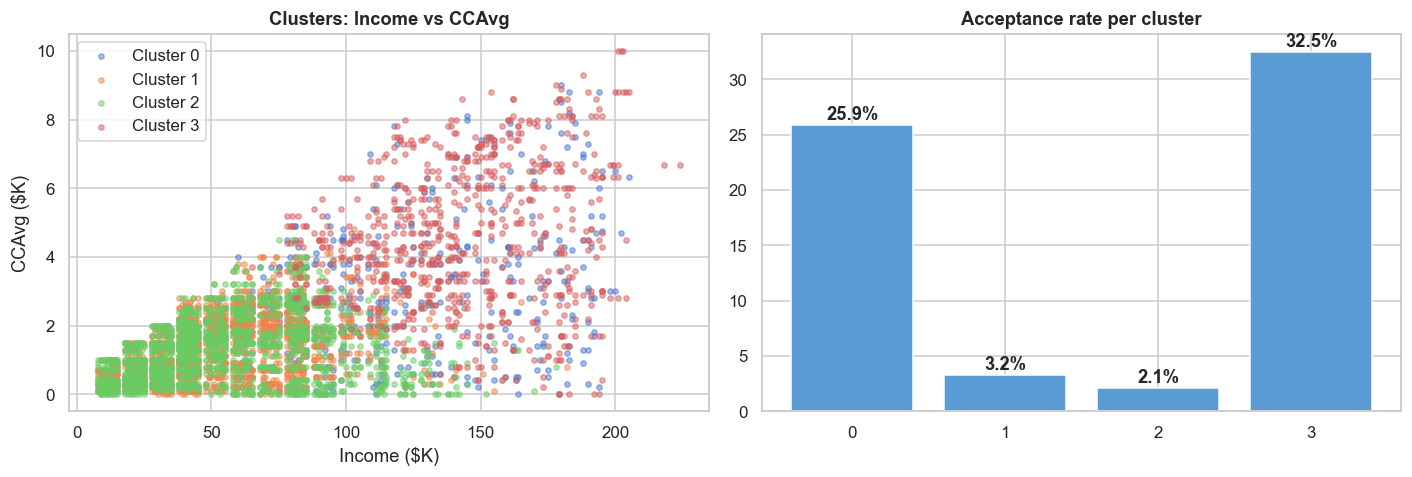

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for c in sorted(df['Cluster'].unique()):
    s = df[df['Cluster'] == c]
    axes[0].scatter(s['Income'], s['CCAvg'], s=12, alpha=0.5, label=f'Cluster {c}')
axes[0].set_xlabel('Income ($K)'); axes[0].set_ylabel('CCAvg ($K)'); axes[0].legend()
axes[0].set_title('Clusters: Income vs CCAvg', fontweight='bold')
rate = df.groupby('Cluster')[TARGET].mean() * 100
bars = axes[1].bar(rate.index.astype(str), rate.values, color='#5B9BD5')
for b, v in zip(bars, rate.values):
    axes[1].text(b.get_x() + b.get_width()/2, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].set_title('Acceptance rate per cluster', fontweight='bold')
plt.tight_layout(); plt.show()
df = df.drop(columns='Cluster')

## 5. Predictive Modeling

**Protocol**
1. Stratified 80/20 split → the **test set is kept aside** until the very end.
2. On the training set: **5-fold stratified cross-validation** to compare models and tune the Random Forest.
3. Main selection metric: **average precision (PR-AUC)** — area under the precision–recall curve, independent of the threshold and informative under class imbalance.
4. Decision threshold chosen on **out-of-fold** training predictions.
5. One single final evaluation on the test set.

In [13]:
features = ['Age', 'Income', 'CCAvg', 'Mortgage', 'Family', 'Education',
            'SecuritiesAccount', 'CDAccount', 'Online', 'CreditCard']
X, y = df[features], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print(f"Train: {len(y_train)} ({y_train.mean():.1%} positives) | Test: {len(y_test)} ({y_test.sum()} positives)")

Train: 4000 (9.6% positives) | Test: 1000 (96 positives)


### 5.1 Model comparison (cross-validation on the training set)

- **Dummy**: always predicts the majority class (reference floor).
- **Logistic regression**: linear baseline. Needs scaling; `Education` is one-hot encoded (its levels are categories, not distances).
- **Decision tree**: interpretable rules.
- **Random forest**: bagging of trees, captures non-linearities and interactions, robust to scale.
- **Gradient boosting** (`HistGradientBoosting`): challenger.

Tree-based models do not need scaling or one-hot encoding.

In [14]:
num_cols = ['Age', 'Income', 'CCAvg', 'Mortgage', 'Family']
prep = make_column_transformer((StandardScaler(), num_cols),
                               (OneHotEncoder(drop='first'), ['Education']),
                               remainder='passthrough')
models = {
    'Dummy (majority)':    DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(prep, LogisticRegression(max_iter=2000)),
    'Decision tree':       DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'Random forest':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'Gradient boosting':   HistGradientBoostingClassifier(random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ['average_precision', 'roc_auc', 'f1', 'precision', 'recall']
rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({'Model': name, **{s: f"{r['test_'+s].mean():.3f} ± {r['test_'+s].std():.3f}" for s in scoring}})
cv_results = pd.DataFrame(rows).set_index('Model')
cv_results

,average_precision,roc_auc,f1,precision,recall
Model,,,,,
Dummy (majority),0.096 ± 0.001,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Logistic regression,0.840 ± 0.049,0.960 ± 0.012,0.736 ± 0.055,0.873 ± 0.059,0.638 ± 0.062
Decision tree,0.945 ± 0.013,0.986 ± 0.006,0.903 ± 0.013,0.937 ± 0.027,0.872 ± 0.035
Random forest,0.983 ± 0.007,0.998 ± 0.001,0.917 ± 0.019,0.975 ± 0.026,0.867 ± 0.038
Gradient boosting,0.982 ± 0.003,0.998 ± 0.000,0.916 ± 0.014,0.953 ± 0.017,0.883 ± 0.034


**Reading.** The linear model is clearly below the tree-based models: acceptance depends on **interactions** (e.g. income × education × family size), which a logistic regression without engineered interaction terms cannot represent. Random forest and gradient boosting are equivalent within the CV standard deviation; we keep the **Random Forest** (fewer hyperparameters, stable, gives feature importances) and tune it.

### 5.2 Random Forest tuning (grid search, 5-fold CV, scoring = average precision)

In [15]:
grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    param_grid={'max_depth': [None, 10, 6],
                'min_samples_leaf': [1, 3, 5],
                'class_weight': [None, 'balanced']},
    scoring='average_precision', cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print(f"Best CV average precision: {grid.best_score_:.3f}")
res = pd.DataFrame(grid.cv_results_)[['params', 'mean_test_score', 'std_test_score']]
res.sort_values('mean_test_score', ascending=False).head(6).round(3)

Best parameters: {'class_weight': None, 'max_depth': 10, 'min_samples_leaf': 1}
Best CV average precision: 0.983


,params,mean_test_score,std_test_score
3,"{'class_weight': None, 'max_depth': 10, 'min_s...",0.983,0.007
0,"{'class_weight': None, 'max_depth': None, 'min...",0.983,0.007
9,"{'class_weight': 'balanced', 'max_depth': None...",0.980,0.008
4,"{'class_weight': None, 'max_depth': 10, 'min_s...",0.979,0.008
1,"{'class_weight': None, 'max_depth': None, 'min...",0.978,0.008
12,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.978,0.008


### 5.3 Decision threshold

`predict()` uses a 0.5 threshold by default. The right threshold depends on the business trade-off between **missed acceptors** (false negatives) and **wasted contacts** (false positives). Here we pick the threshold that maximises F1 on **out-of-fold predictions of the training set**, so the test set stays untouched.

In [16]:
best_rf = grid.best_estimator_
oof = cross_val_predict(best_rf, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THRESHOLD = float(thr[np.argmax(f1)])
print(f"Chosen threshold (max out-of-fold F1): {THRESHOLD:.2f}")
for t in [0.3, 0.5, THRESHOLD]:
    p = (oof >= t).astype(int)
    print(f"  t={t:.2f}  precision={precision_score(y_train, p):.3f}  recall={recall_score(y_train, p):.3f}  F1={f1_score(y_train, p):.3f}")

Chosen threshold (max out-of-fold F1): 0.38
  t=0.30  precision=0.907  recall=0.938  F1=0.922
  t=0.50  precision=0.968  recall=0.867  F1=0.915
  t=0.38  precision=0.941  recall=0.922  F1=0.932


### 5.4 Final evaluation on the test set

In [17]:
best_rf.fit(X_train, y_train)
proba_test = best_rf.predict_proba(X_test)[:, 1]
y_pred = (proba_test >= THRESHOLD).astype(int)

print(f"Average precision (PR-AUC): {average_precision_score(y_test, proba_test):.3f}")
print(f"ROC-AUC                   : {roc_auc_score(y_test, proba_test):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=['Declined', 'Accepted'], digits=3))

# Same evaluation for the logistic baseline and the decision tree (trained on the full training set)
for name in ['Logistic regression', 'Decision tree']:
    m = models[name].fit(X_train, y_train); p = m.predict_proba(X_test)[:, 1]
    print(f"{name:20s} test PR-AUC = {average_precision_score(y_test, p):.3f}")

Average precision (PR-AUC): 0.992
ROC-AUC                   : 0.999

              precision    recall  f1-score   support

    Declined      0.997     0.993     0.995       904
    Accepted      0.939     0.969     0.954        96

    accuracy                          0.991      1000
   macro avg      0.968     0.981     0.974      1000
weighted avg      0.991     0.991     0.991      1000

Logistic regression  test PR-AUC = 0.858
Decision tree        test PR-AUC = 0.923


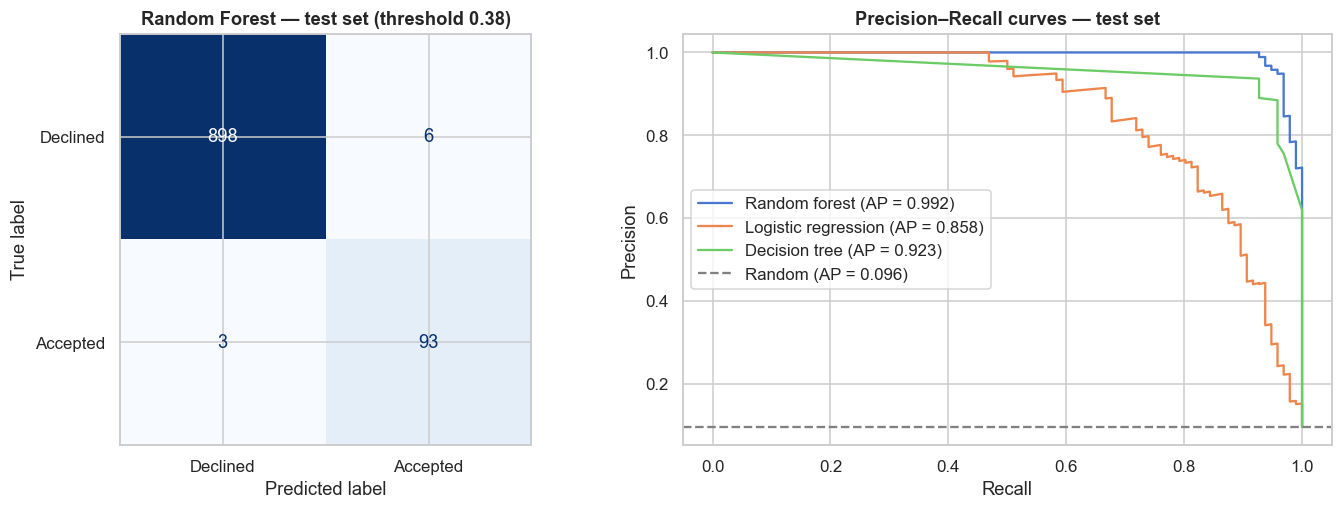

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Declined', 'Accepted']).plot(
    ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'Random Forest — test set (threshold {THRESHOLD:.2f})', fontweight='bold')

for name, m in [('Random forest', best_rf), ('Logistic regression', models['Logistic regression']),
                ('Decision tree', models['Decision tree'])]:
    p = m.predict_proba(X_test)[:, 1]
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label=f'{name} (AP = {average_precision_score(y_test, p):.3f})')
axes[1].axhline(y_test.mean(), ls='--', color='grey', label=f'Random (AP = {y_test.mean():.3f})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].legend()
axes[1].set_title('Precision–Recall curves — test set', fontweight='bold')
plt.tight_layout(); plt.show()

### 5.5 Campaign targeting  cumulative gains

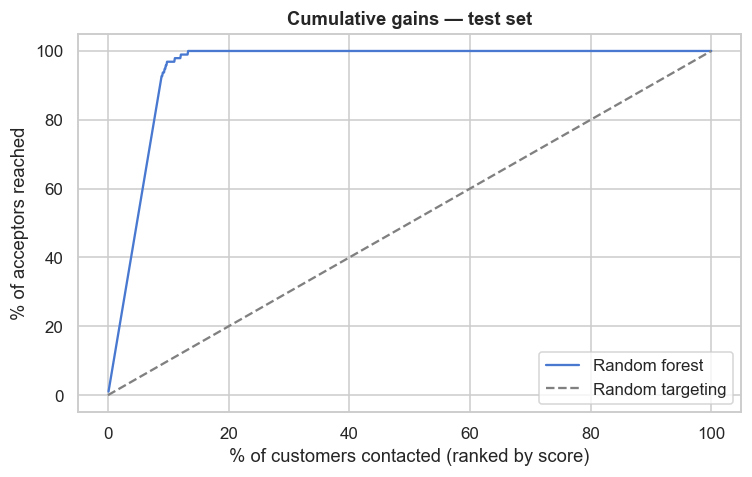

Top 5% (50 customers): 50/96 acceptors reached (52%), conversion in target = 100.0% (vs 9.6% overall)
Top 10% (100 customers): 93/96 acceptors reached (97%), conversion in target = 93.0% (vs 9.6% overall)
Top 15% (150 customers): 96/96 acceptors reached (100%), conversion in target = 64.0% (vs 9.6% overall)
Top 20% (200 customers): 96/96 acceptors reached (100%), conversion in target = 48.0% (vs 9.6% overall)


In [19]:
order = np.argsort(-proba_test)
captured = np.cumsum(y_test.values[order]) / y_test.sum()
share = np.arange(1, len(order) + 1) / len(order)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(share * 100, captured * 100, label='Random forest')
ax.plot([0, 100], [0, 100], '--', color='grey', label='Random targeting')
ax.set_xlabel('% of customers contacted (ranked by score)'); ax.set_ylabel('% of acceptors reached')
ax.set_title('Cumulative gains — test set', fontweight='bold'); ax.legend()
plt.tight_layout(); plt.show()

for q in [0.05, 0.10, 0.15, 0.20]:
    k = int(round(q * len(order)))
    hit = y_test.values[order[:k]]
    print(f"Top {q:.0%} ({k} customers): {hit.sum()}/{y_test.sum()} acceptors reached "
          f"({hit.sum()/y_test.sum():.0%}), conversion in target = {hit.mean():.1%} (vs {y_test.mean():.1%} overall)")

### 5.6 Feature importance

Two views:
- **Impurity-based importance** (built into the forest): fast, but biased toward continuous variables with many split points.
- **Permutation importance** on the test set (drop in average precision when a feature is shuffled): measures what the model really relies on.

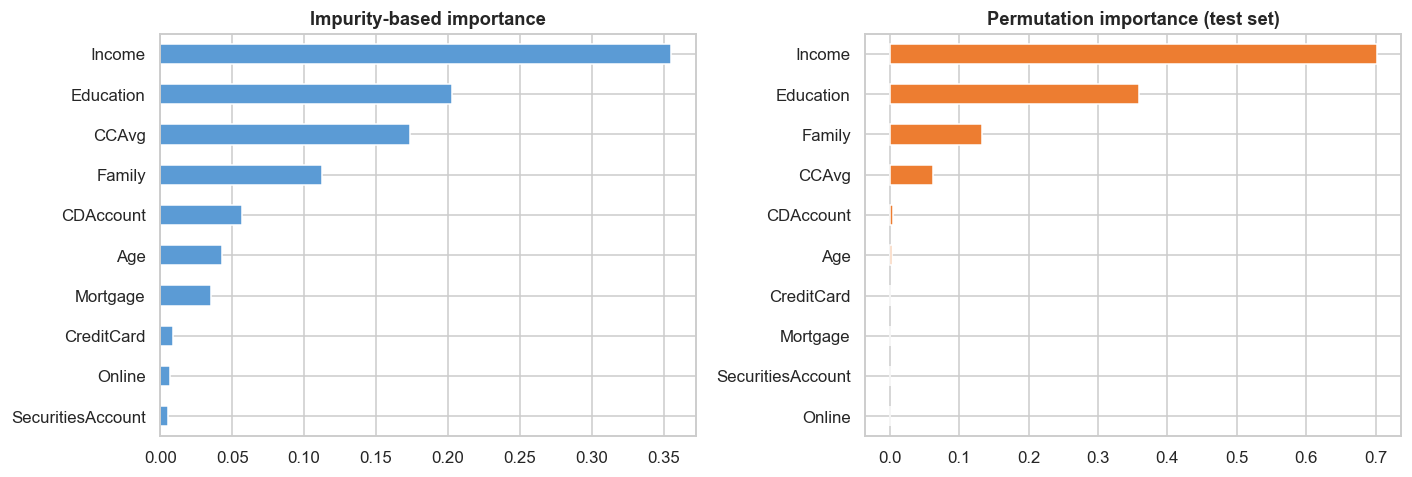

,Impurity-based,Permutation (Δ AP)
Income,0.355,0.702
Education,0.203,0.359
Family,0.112,0.132
CCAvg,0.174,0.063
CDAccount,0.057,0.005
Age,0.043,0.003
CreditCard,0.009,0.001
Mortgage,0.035,0.001
SecuritiesAccount,0.005,0.000
Online,0.007,-0.000


In [20]:
perm = permutation_importance(best_rf, X_test, y_test, scoring='average_precision',
                              n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({'Impurity-based': best_rf.feature_importances_,
                    'Permutation (Δ AP)': perm.importances_mean}, index=features)
imp = imp.sort_values('Permutation (Δ AP)', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
imp['Impurity-based'].sort_values().plot.barh(ax=axes[0], color='#5B9BD5')
axes[0].set_title('Impurity-based importance', fontweight='bold')
imp['Permutation (Δ AP)'].sort_values().plot.barh(ax=axes[1], color='#ED7D31')
axes[1].set_title('Permutation importance (test set)', fontweight='bold')
plt.tight_layout(); plt.show()
imp.round(3)

**Interpretable view:** a shallow decision tree (depth 3) to read the main rules.

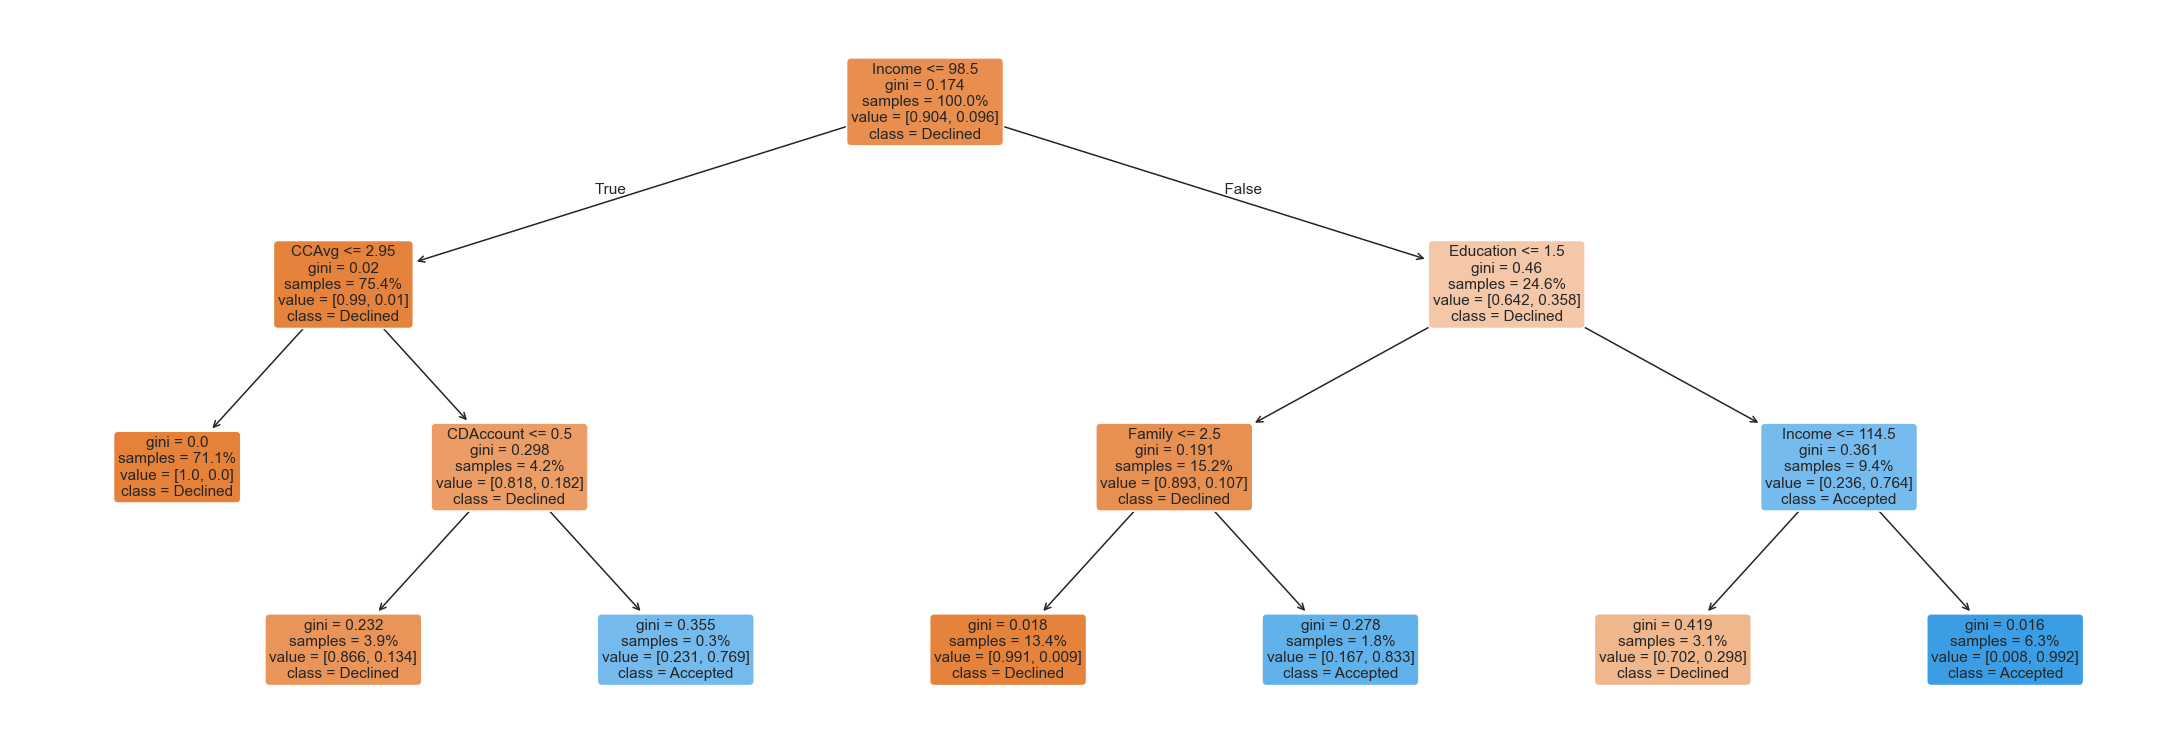

In [21]:
dt_viz = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(dt_viz, feature_names=features, class_names=['Declined', 'Accepted'],
          filled=True, rounded=True, fontsize=10, proportion=True, ax=ax)
plt.tight_layout(); plt.show()

## 6. Conclusions & Business Insights

### 🎯 Model performance

| Model | CV average precision (train, 5-fold) | Test average precision |
|-------|------|------|
| Dummy (majority class) | 0.096 | — |
| Logistic regression | 0.840 ± 0.049 | 0.858 |
| Decision tree (depth 5) | 0.945 ± 0.013 | 0.923 |
| **Random forest (tuned)** | **0.983 ± 0.007** | **0.992** |
| Gradient boosting | 0.983 ± 0.004 | — |

Final Random Forest (`max_depth=10`, 300 trees, no class weighting, threshold 0.38) on the **test set** (1,000 customers, 96 acceptors):
**precision 93.9%, recall 96.9%, F1 0.954** — 93 acceptors found, 3 missed, 6 false positives.
The test score is slightly above the CV estimate: with only 96 positives in the test set, the **CV figure (≈ 0.98) is the more reliable estimate** of future performance.

### 🔑 Key findings
| Factor | Evidence |
|--------|---------|
| **Income** | Main driver. Acceptance 36.1% above $100K vs 1.1% below. First in both importance measures. |
| **Education** | Graduate / professional customers accept ~3× more than undergraduates (13.0–13.7% vs 4.4%). Second in permutation importance. |
| **Family size** | Families of 3–4 accept more (11–13% vs 7–8%). |
| **CCAvg** | Strongly correlated with acceptance, but partly redundant with Income once both are in the model. |
| **CD Account** | 46.4% acceptance vs 7.2% — strong marginal signal, but almost no extra predictive power once Income and the other variables are known. |
| **Online, CreditCard** | No difference in acceptance rate (≈ 9.5% vs 9.8%). Not useful for targeting. |

### 💡 Marketing recommendations
1. **Score every customer** with the Random Forest and contact them in decreasing order of score: on the test set, the top 10% of customers contains **93 of the 96 acceptors (97%)**, with a 93% conversion rate in the target vs 9.6% overall.
2. The **high-income segments** found by K-Means (clusters with Income > $110K) concentrate acceptors (26–32% acceptance vs 2–3% elsewhere).
3. **CD Account holders** are a natural cross-sell audience (46% acceptance), even though the score already captures most of this signal through income.

### ⚠️ Limitations
- **Small number of positives** (480): test metrics vary from one split to another; CV standard deviations should be kept in mind.
- **Threshold chosen by F1**, which gives equal weight to precision and recall. With real campaign costs (cost of a contact vs margin of a loan), the threshold should be set by **expected profit**.
- **Historical campaign data:** the model learns who accepted *the past offer*. A new offer, rate or channel may change behaviour; performance must be monitored after deployment.
- **K-Means:** low silhouette scores (< 0.3) — the segments are descriptive, not natural clusters. `Education` and `Family` are ordinal variables treated as continuous.
- **Probabilities not calibrated:** scores are used for ranking; calibration (e.g. isotonic) would be needed to read them as true probabilities.

### 🚀 Next steps
- Profit-based threshold and campaign-size optimisation.
- Probability calibration and SHAP values for individual explanations.
- Logistic regression with interaction terms (Income × Education, Income × Family) as an interpretable alternative.
